# Divorce Analysis — Clustering with DBSCAN

**Input:** `report_outputs/final_data/divorce_cleaned.csv` (output of `EDA_Preprocessing_v2.ipynb`), plus the
feature list (`final_feature_sets.csv`) and the per-year scaler parameters (`final_scaler_params.csv`) saved by
that notebook, so the features here are encoded exactly like everywhere else in the project.

**Tasks**
1. Cluster a sample of respondents with DBSCAN (eps chosen from the k-distance graph, then a small grid).
2. Evaluate with Silhouette, Calinski-Harabasz and Davies-Bouldin.
3. Visualize the clusters with PCA (2D and 3D) and t-SNE (2D).
4. Discuss whether DBSCAN suits this dataset and compare it with K-Means.

**For teammates.** Every function in Section 1 is self-contained. Results use one table layout
(`algorithm, params, n_clusters, noise_pct, largest_cluster_pct, silhouette, calinski_harabasz, davies_bouldin`),
so other algorithms can be added with `cluster_metrics(...)`. The sample, its encoded matrix and its labels are
saved, so every algorithm can be scored on **the same rows**.

**Outputs:** figures in `report_outputs/figures/clustering/`, tables in `report_outputs/final_reports/clustering_*.csv`.

## 0. Configuration

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# ---- paths ------------------------------------------------------------------
OUT_ROOT = Path("report_outputs")
DATA_FILE = OUT_ROOT / "final_data" / "divorce_cleaned.csv"
FEATURE_SETS_FILE = OUT_ROOT / "final_reports" / "final_feature_sets.csv"
SCALER_FILE = OUT_ROOT / "final_reports" / "final_scaler_params.csv"
FIG_DIR = OUT_ROOT / "figures" / "clustering"
TABLE_DIR = OUT_ROOT / "final_reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- data -------------------------------------------------------------------
YEAR, TARGET, SPLIT_COL = "YEAR", "DIVINYR", "SPLIT"
INDICATOR = "FTOTINC_POVERTY_MISSING"
FEATURE_SET = "reduced"     # "reduced" (top-15 variables by mutual information) or "full" (21 variables)
SPLIT = "train"             # cluster training rows only
ROWS_PER_YEAR = 50000       # DBSCAN needs pairwise neighbourhoods -> work on a sample (equal rows per year)
SEED = 0

# ---- DBSCAN grid ------------------------------------------------------------
MIN_SAMPLES_GRID = None     # None -> [10, n_features, 2 * n_features] (2*dim is the usual rule of thumb)
EPS_QUANTILES = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   # eps candidates = quantiles of the k-distance curve
MAX_NOISE = 0.25            # a configuration may label at most 25% of the rows as noise to be selected

# ---- evaluation / plots -----------------------------------------------------
KMEANS_K = range(2, 9)
SILHOUETTE_ROWS = 10_000
TSNE_ROWS = 50000
NOISE_COLOR = "#BDBDBD"
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

## 1. Helper functions

Data → features → clustering → metrics → plots. Nothing here depends on global state except the constants above.

In [2]:
def feature_variables(feature_sets_file, which="reduced"):
    """Numeric and categorical variables of the 'reduced' or 'full' feature set."""
    fs = pd.read_csv(feature_sets_file)
    fs = fs[fs[f"in_{which}_set"]]
    return (fs.loc[fs.type == "numeric", "variable"].tolist(),
            fs.loc[fs.type == "categorical", "variable"].tolist())


def load_sample(path, columns, rows_per_year, split="train", seed=0):
    """Random sample with the same number of rows from each survey year."""
    df = pd.read_csv(path, usecols=list(dict.fromkeys([YEAR, TARGET, SPLIT_COL, *columns])))
    df = df[df[SPLIT_COL] == split]
    return df.groupby(YEAR, group_keys=False).sample(n=rows_per_year, random_state=seed).reset_index(drop=True)


def encode_features(df, num_cols, cat_cols, scaler_file):
    """Same design matrix as the preprocessing notebook:
    z-score within each year (training-row mean/std) + missing indicator + one-hot (missing = its own level)."""
    params = pd.read_csv(scaler_file)
    z = pd.DataFrame(index=df.index)
    for c in num_cols:
        p = params[params.variable == c].set_index("year")
        z[c] = (df[c] - df[YEAR].map(p["mean"])) / df[YEAR].map(p["std"])
    parts = [z]
    if INDICATOR in df:
        parts.append(df[[INDICATOR]].astype(float))
    parts.append(pd.get_dummies(df[cat_cols], prefix_sep="__", dummy_na=True, dtype=float))
    X = pd.concat(parts, axis=1)
    return X.loc[:, X.std() > 0]          # drop constant columns (e.g. an empty NaN level)

In [3]:
def k_distances(X, k):
    """Sorted distance of every point to its k-th nearest neighbour (the point itself counts, as in DBSCAN)."""
    dist, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
    return np.sort(dist[:, -1])


def elbow_index(curve):
    """Knee of an increasing convex curve: the point farthest below the chord from first to last point."""
    x = np.linspace(0, 1, len(curve))
    y = (curve - curve[0]) / (curve[-1] - curve[0])
    return int(np.argmax(x - y))


def relabel_by_size(labels):
    """Cluster 0 = largest, 1 = next, ...; noise stays -1 (makes colours and tables stable)."""
    ids, counts = np.unique(labels[labels != -1], return_counts=True)
    mapping = {old: new for new, old in enumerate(ids[np.argsort(-counts)])}
    return np.array([mapping.get(l, -1) for l in labels])


def cluster_metrics(X, labels, algorithm, params, sample_size=SILHOUETTE_ROWS, seed=SEED):
    """One result row. Noise points (-1) are excluded from the three internal indices
    (they belong to no cluster), so always read the scores together with noise_pct."""
    labels = np.asarray(labels)
    mask = labels != -1
    ids, counts = np.unique(labels[mask], return_counts=True)
    row = {"algorithm": algorithm, "params": params, "n_clusters": len(ids),
           "noise_pct": 100 * (1 - mask.mean()),
           "largest_cluster_pct": 100 * counts.max() / len(labels) if len(ids) else 0.0,
           "silhouette": np.nan, "calinski_harabasz": np.nan, "davies_bouldin": np.nan}
    if len(ids) >= 2:
        Xc, lc = X[mask], labels[mask]
        row["silhouette"] = silhouette_score(Xc, lc, sample_size=min(sample_size, len(lc)), random_state=seed)
        row["calinski_harabasz"] = calinski_harabasz_score(Xc, lc)
        row["davies_bouldin"] = davies_bouldin_score(Xc, lc)
    return row


def run_dbscan_grid(X, kdist_by_min_samples, eps_quantiles):
    """DBSCAN for every (min_samples, eps); eps = k-distance quantiles + the k-distance elbow."""
    rows, labels = [], {}
    for ms, kd in kdist_by_min_samples.items():
        eps_values = {round(float(e), 3) for e in np.quantile(kd, eps_quantiles)}
        eps_values.add(round(float(kd[elbow_index(kd)]), 3))
        for eps in sorted(eps_values):
            lab = relabel_by_size(DBSCAN(eps=eps, min_samples=ms, n_jobs=-1).fit_predict(X))
            labels[(ms, eps)] = lab
            rows.append({"min_samples": ms, "eps": eps,
                         **cluster_metrics(X, lab, "DBSCAN", f"eps={eps}, min_samples={ms}")})
    return pd.DataFrame(rows), labels


def select_best(grid, max_noise=MAX_NOISE):
    """Highest silhouette among configurations with >= 2 clusters and at most `max_noise` noise."""
    valid = grid[grid.n_clusters >= 2]
    ok = valid[valid.noise_pct <= 100 * max_noise]
    return (ok if len(ok) else valid).sort_values("silhouette", ascending=False).iloc[0]

In [4]:
def label_style(lab, max_colored=len(CLUSTER_COLORS)):
    """Colour and legend text of a label: noise grey, the 8 largest clusters coloured, the rest folded."""
    if lab == -1:
        return NOISE_COLOR, "noise"
    if lab < max_colored:
        return CLUSTER_COLORS[lab], f"cluster {lab}"
    return "#6f6f6f", f"clusters {max_colored}+"


def scatter_clusters(ax, Z, labels, title, s=5):
    """2D or 3D scatter (dimension taken from Z); noise drawn first so clusters sit on top."""
    seen = set()
    for lab in sorted(np.unique(labels)):
        color, name = label_style(lab)
        m = labels == lab
        ax.scatter(*Z[m].T, s=s, c=color, alpha=0.7, linewidths=0,
                   label=None if name in seen else f"{name}")
        seen.add(name)
    ax.set_title(title, fontsize=11)
    ax.legend(markerscale=3, fontsize=8, frameon=False, loc="best")
    for side in ("top", "right"):
        if side in ax.spines:
            ax.spines[side].set_visible(False)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load and encode a sample

In [5]:
num_cols, cat_cols = feature_variables(FEATURE_SETS_FILE, FEATURE_SET)
sample = load_sample(DATA_FILE, num_cols + cat_cols + [INDICATOR], ROWS_PER_YEAR, SPLIT, SEED)
X_df = encode_features(sample, num_cols, cat_cols, SCALER_FILE)
X = X_df.to_numpy()

print(f"Feature set: {FEATURE_SET}  ({len(num_cols)} numeric + {len(cat_cols)} categorical variables)")
print(f"Sample: {len(sample):,} rows ({ROWS_PER_YEAR:,} per year), {sample[TARGET].mean():.2%} divorced")
print(f"Design matrix: {X.shape[0]:,} x {X.shape[1]} columns")

Feature set: reduced  (9 numeric + 6 categorical variables)
Sample: 150,000 rows (50,000 per year), 1.06% divorced
Design matrix: 150,000 x 38 columns


## 3. Choosing `min_samples` and `eps` — k-distance graph

For each candidate `min_samples = k`, the sorted distance to the k-th neighbour shows how dense the data is.
A clear "knee" marks a natural `eps`: below it points are in dense regions, above it they are outliers.

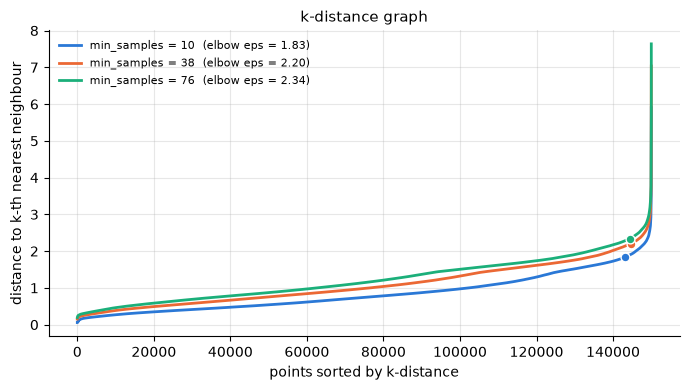

In [6]:
min_samples_grid = MIN_SAMPLES_GRID or [10, X.shape[1], 2 * X.shape[1]]
kdist = {k: k_distances(X, k) for k in min_samples_grid}

fig, ax = plt.subplots(figsize=(7, 4))
for color, (k, kd) in zip(CLUSTER_COLORS, kdist.items()):
    i = elbow_index(kd)
    ax.plot(np.arange(len(kd)), kd, lw=2, color=color, label=f"min_samples = {k}  (elbow eps = {kd[i]:.2f})")
    ax.scatter(i, kd[i], s=40, color=color, edgecolor="white", zorder=3)
ax.set_xlabel("points sorted by k-distance")
ax.set_ylabel("distance to k-th nearest neighbour")
ax.set_title("k-distance graph", fontsize=11)
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
save(fig, "dbscan_01_k_distance.png")

## 4. DBSCAN parameter grid and evaluation

In [7]:
grid, grid_labels = run_dbscan_grid(X, kdist, EPS_QUANTILES)
grid.to_csv(TABLE_DIR / "clustering_dbscan_grid.csv", index=False)
grid.drop(columns=["algorithm", "params"]).round(3)

,min_samples,eps,n_clusters,noise_pct,largest_cluster_pct,silhouette,calinski_harabasz,davies_bouldin
0,10,0.506,149,61.375,6.691,-0.051,1201.643,1.425
1,10,0.615,234,50.689,7.130,-0.096,879.958,1.531
2,10,0.741,164,40.135,18.590,-0.158,828.929,1.292
3,10,0.871,158,30.161,19.843,-0.148,917.716,1.504
4,10,1.034,184,21.335,20.596,-0.129,823.206,1.683
5,10,1.295,203,13.507,21.039,-0.132,767.935,2.037
6,10,1.615,2,4.305,93.289,0.059,2613.020,1.869
7,10,1.832,1,1.424,98.576,NaN,NaN,NaN
8,38,0.711,29,58.053,15.821,0.015,4164.861,1.445
9,38,0.844,47,46.696,17.899,-0.054,2961.131,1.469


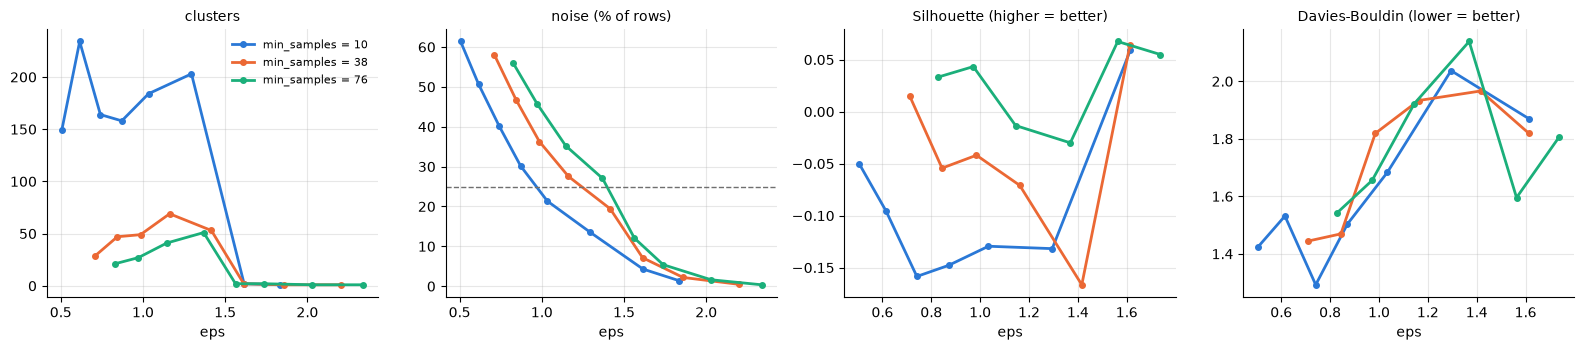

In [8]:
metrics = [("n_clusters", "clusters"), ("noise_pct", "noise (% of rows)"),
           ("silhouette", "Silhouette (higher = better)"), ("davies_bouldin", "Davies-Bouldin (lower = better)")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (col, title) in zip(axes, metrics):
    for color, (ms, g) in zip(CLUSTER_COLORS, grid.groupby("min_samples")):
        ax.plot(g.eps, g[col], marker="o", ms=4, lw=2, color=color, label=f"min_samples = {ms}")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("eps")
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].axhline(100 * MAX_NOISE, color="#6f6f6f", ls="--", lw=1)
axes[0].legend(frameon=False, fontsize=8)
save(fig, "dbscan_02_parameter_grid.png")

In [9]:
best = select_best(grid, MAX_NOISE)
best_key = (int(best.min_samples), float(best.eps))
labels = grid_labels[best_key]
print(f"Selected: eps = {best_key[1]}, min_samples = {best_key[0]}")
print(f"Cluster sizes: {pd.Series(labels).value_counts().sort_index().to_dict()}  (-1 = noise)")
best.to_frame("selected DBSCAN").T

Selected: eps = 1.563, min_samples = 76
Cluster sizes: {-1: 18084, 0: 128814, 1: 3102}  (-1 = noise)


,min_samples,eps,algorithm,params,n_clusters,noise_pct,largest_cluster_pct,silhouette,calinski_harabasz,davies_bouldin
selected DBSCAN,76,1.563,DBSCAN,"eps=1.563, min_samples=76",2,12.056,85.876,0.06747,2837.735672,1.595492


## 5. Visualizing the clusters

PCA is a linear projection (axes keep their meaning, distances are preserved approximately);
t-SNE is non-linear and only preserves local neighbourhoods, so distances *between* t-SNE groups are not meaningful.
Both are fitted on the same encoded matrix DBSCAN used.

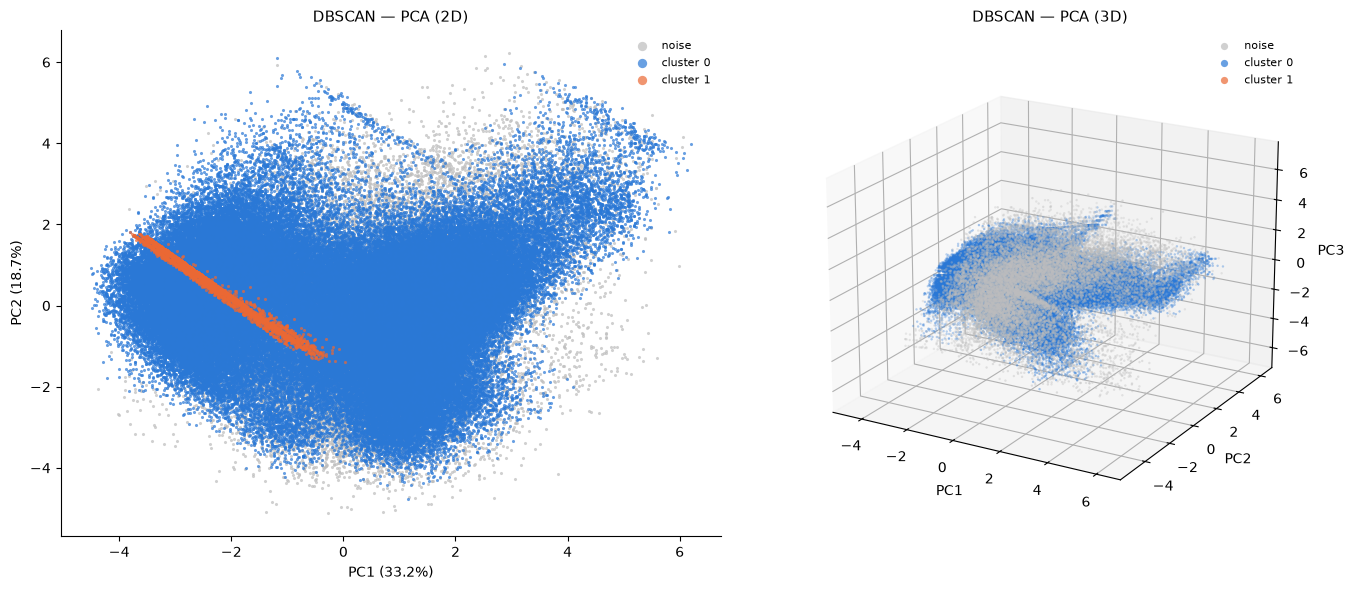

Variance explained by PC1-3: 61.8%


In [10]:
pca = PCA(n_components=3, random_state=SEED).fit(X)
Z_pca = pca.transform(X)
ev = pca.explained_variance_ratio_

fig = plt.figure(figsize=(14, 6))
ax2 = fig.add_subplot(1, 2, 1)
scatter_clusters(ax2, Z_pca[:, :2], labels, "DBSCAN — PCA (2D)")
ax2.set_xlabel(f"PC1 ({ev[0]:.1%})"); ax2.set_ylabel(f"PC2 ({ev[1]:.1%})")
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
scatter_clusters(ax3, Z_pca, labels, "DBSCAN — PCA (3D)", s=3)
ax3.set_xlabel("PC1"); ax3.set_ylabel("PC2"); ax3.set_zlabel("PC3")
ax3.view_init(elev=20, azim=-60)
save(fig, "dbscan_03_pca.png")
print(f"Variance explained by PC1-3: {ev.sum():.1%}")

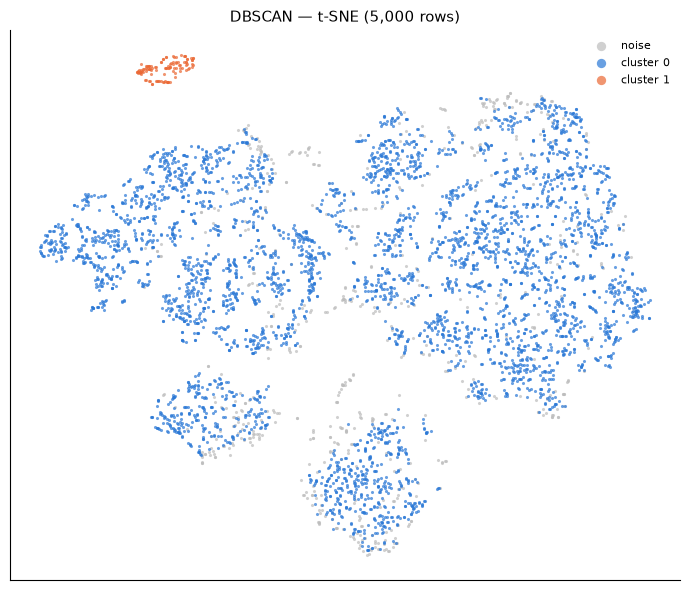

In [17]:
rng = np.random.default_rng(SEED)
tsne_idx = np.sort(rng.choice(len(X), size=min(TSNE_ROWS, len(X)), replace=False))
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X[tsne_idx])

fig, ax = plt.subplots(figsize=(7, 6))
scatter_clusters(ax, Z_tsne, labels[tsne_idx], f"DBSCAN — t-SNE ({len(tsne_idx):,} rows)")
ax.set_xticks([]); ax.set_yticks([])
save(fig, "dbscan_04_tsne.png")

## 6. What the clusters contain

Clustering is unsupervised — `DIVINYR` was **not** used. Its rate per cluster shows whether the
structure DBSCAN found is related to recent divorce. Numeric columns are shown in original units.

In [12]:
def cluster_profile(df, labels, num_cols, cat_cols):
    """Size, divorce rate, numeric medians and most common level of each categorical, per cluster."""
    d = df.assign(cluster=labels)
    g = d.groupby("cluster")
    prof = pd.DataFrame({"n_rows": g.size(), "pct_rows": 100 * g.size() / len(d),
                         "pct_divorced": 100 * g[TARGET].mean()})
    prof = prof.join(g[num_cols].median().add_suffix(" (median)"))
    for c in cat_cols:
        prof[c] = g[c].agg(lambda s: s.fillna("N/A").value_counts(normalize=True).pipe(
            lambda v: f"{v.index[0]} ({v.iloc[0]:.0%})"))
    return prof.rename(index={-1: "noise"})


profile = cluster_profile(sample, labels, num_cols, cat_cols)
profile.to_csv(TABLE_DIR / "clustering_dbscan_profile.csv")
profile.round(1).T

cluster,noise,0,1
n_rows,18084,128814,3102
pct_rows,12.1,85.9,2.1
pct_divorced,1.6,1.0,1.5
YRMARR (median),1998.0,1991.0,1980.0
AGE (median),52.0,56.0,76.0
FAMSIZE (median),3.0,2.0,1.0
VALUEH (median),110000.0,190000.0,0.0
RENT (median),0.0,0.0,0.0
FTOTINC (median),89250.0,74850.0,71000.0
INCEARN (median),13000.0,19200.0,0.0
